# Vector Databases — The Math Behind Semantic Search

## Why Vector Databases Exist

Traditional databases answer **exact** questions: *"Find user where id = 42"*.

ML systems need **semantic** questions: *"Find the 10 documents most similar in meaning to this query"*.

The machinery that makes this possible:
1. **Embeddings**: Text, images, audio → dense float vectors (e.g., 1536-dimensional for OpenAI ada-002)
2. **Distance metrics**: Measure similarity between vectors
3. **Approximate Nearest Neighbor (ANN) algorithms**: Find similar vectors without scanning all of them
4. **Vector databases**: Infrastructure built around these algorithms

**Powers**: RAG (retrieval-augmented generation), semantic search, recommendation systems, duplicate detection, anomaly detection.

## Distance Metrics — The Foundation

Everything in a vector database starts with a distance function. Your choice of metric shapes what "similar" means.

### Euclidean Distance (L2)
$$d_2(\mathbf{a}, \mathbf{b}) = \sqrt{\sum_{i=1}^{d}(a_i - b_i)^2}$$
Measures straight-line distance in vector space. Sensitive to vector magnitude.

### Cosine Similarity
$$\text{cos}(\theta) = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\| \cdot \|\mathbf{b}\|} = \frac{\sum_{i} a_i b_i}{\sqrt{\sum_i a_i^2} \cdot \sqrt{\sum_i b_i^2}}$$
Measures the **angle** between vectors. Magnitude-invariant — a short and long document with the same topic score similarly. **Best for text embeddings**.

### Dot Product
$$\mathbf{a} \cdot \mathbf{b} = \sum_{i=1}^{d} a_i b_i$$
Raw inner product. If vectors are L2-normalized, equals cosine similarity. Used in maximum inner product search (MIPS) — e.g., recommendation systems where magnitude encodes popularity.

### Manhattan Distance (L1)
$$d_1(\mathbf{a}, \mathbf{b}) = \sum_{i=1}^{d} |a_i - b_i|$$
Sum of absolute differences. More robust to outlier dimensions.

In [1]:
import numpy as np

# ── Implement all distance metrics from scratch ───────────────────────────────
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

def cosine_distance(a, b):
    return 1 - cosine_similarity(a, b)

def dot_product(a, b):
    return np.dot(a, b)

def manhattan(a, b):
    return np.sum(np.abs(a - b))

# Simulate word embeddings (2D for visualization)
# "king" and "queen" should be closer than "king" and "apple"
king   = np.array([0.9, 0.8])
queen  = np.array([0.85, 0.85])
man    = np.array([0.7, 0.3])
woman  = np.array([0.65, 0.35])
apple  = np.array([-0.5, 0.2])
query  = np.array([0.88, 0.82])   # query vector

vectors = {'king': king, 'queen': queen, 'man': man, 'woman': woman, 'apple': apple}

print("=== Distance from query to each word ===")
print(f"{'Word':<10} {'Euclidean':>12} {'Cosine Dist':>13} {'Manhattan':>11} {'Dot Prod':>10}")
print("-" * 60)
for name, vec in vectors.items():
    print(f"{name:<10} {euclidean(query, vec):>12.4f} {cosine_distance(query, vec):>13.4f} "
          f"{manhattan(query, vec):>11.4f} {dot_product(query, vec):>10.4f}")

print("\n→ Note: 'queen' and 'king' closest by all metrics; 'apple' farthest")
print("→ Cosine insensitive to vector magnitude — right choice for text")

=== Distance from query to each word ===
Word          Euclidean   Cosine Dist   Manhattan   Dot Prod
------------------------------------------------------------
king             0.0283        0.0003      0.0400     1.4480
queen            0.0424        0.0006      0.0600     1.4450
man              0.5503        0.0590      0.7000     0.8620
woman            0.5233        0.0326      0.7000     0.8590
apple            1.5129        1.4261      2.0000    -0.2760

→ Note: 'queen' and 'king' closest by all metrics; 'apple' farthest
→ Cosine insensitive to vector magnitude — right choice for text


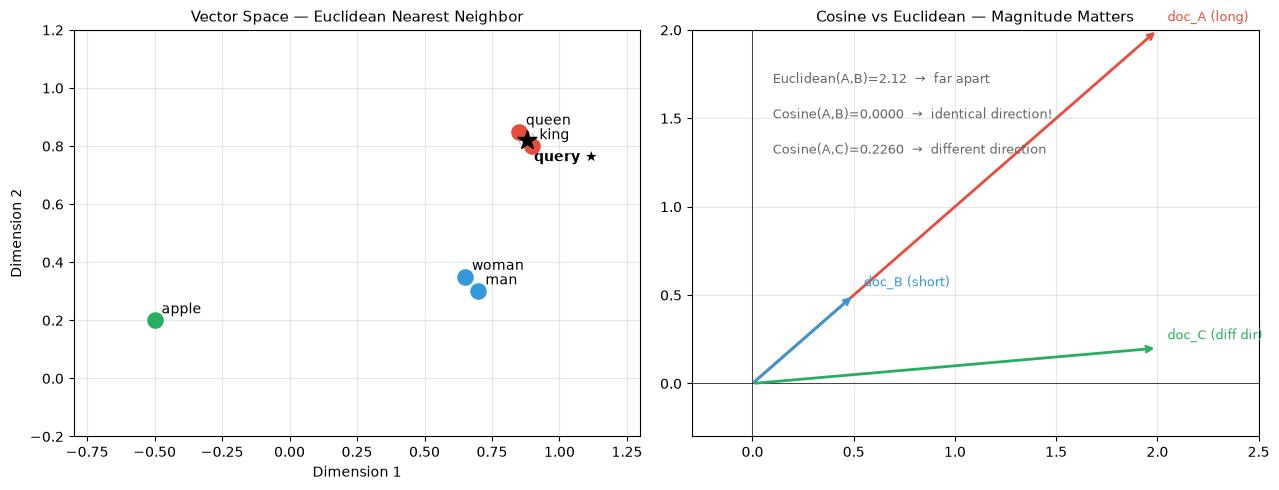

Use cosine for text — same topic = same direction regardless of document length


In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: all vectors + query
ax = axes[0]
ax.set_title('Vector Space — Euclidean Nearest Neighbor', fontsize=11)
colors = {'king':'#E74C3C','queen':'#E74C3C','man':'#3498DB','woman':'#3498DB','apple':'#27AE60'}
for name, vec in vectors.items():
    ax.scatter(*vec, s=120, color=colors[name], zorder=3)
    ax.annotate(name, vec, textcoords='offset points', xytext=(5,5), fontsize=10)
ax.scatter(*query, s=200, color='black', marker='*', zorder=4)
ax.annotate('query ★', query, textcoords='offset points', xytext=(5,-15), fontsize=10, fontweight='bold')
# Draw circle showing nearest neighbor
nn_dist = min(euclidean(query, v) for v in vectors.values())
circle = plt.Circle(query, nn_dist, fill=False, linestyle='--', color='gray', alpha=0.5)
ax.add_patch(circle)
ax.set_xlim(-0.8, 1.3); ax.set_ylim(-0.2, 1.2)
ax.set_xlabel('Dimension 1'); ax.set_ylabel('Dimension 2')
ax.grid(True, alpha=0.3)

# Right: short vs long vector — cosine same, euclidean different
ax2 = axes[1]
ax2.set_title('Cosine vs Euclidean — Magnitude Matters', fontsize=11)
v1 = np.array([2.0, 2.0])   # long vector, same direction
v2 = np.array([0.5, 0.5])   # short vector, same direction
v3 = np.array([2.0, 0.2])   # long vector, different direction
origin = np.array([0, 0])
for v, name, col in [(v1,'doc_A (long)','#E74C3C'),(v2,'doc_B (short)','#3498DB'),(v3,'doc_C (diff dir)','#27AE60')]:
    ax2.annotate('', xy=v, xytext=origin, arrowprops=dict(arrowstyle='->', color=col, lw=2))
    ax2.text(v[0]+0.05, v[1]+0.05, name, color=col, fontsize=9)
ax2.text(0.1, 1.7, f'Euclidean(A,B)={euclidean(v1,v2):.2f}  →  far apart', fontsize=9, color='#666')
ax2.text(0.1, 1.5, f'Cosine(A,B)={cosine_distance(v1,v2):.4f}  →  identical direction!', fontsize=9, color='#666')
ax2.text(0.1, 1.3, f'Cosine(A,C)={cosine_distance(v1,v3):.4f}  →  different direction', fontsize=9, color='#666')
ax2.set_xlim(-0.3, 2.5); ax2.set_ylim(-0.3, 2.0)
ax2.axhline(0, color='black', lw=0.5); ax2.axvline(0, color='black', lw=0.5)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('distance_metrics.png', dpi=120, bbox_inches='tight')
plt.show()
print('Use cosine for text — same topic = same direction regardless of document length')

## The Curse of Dimensionality

Why can't we just use brute-force KNN on 1M vectors at 1536 dimensions?

**Volume of a d-dimensional unit sphere**:
$$V_d(r) = \frac{\pi^{d/2}}{\Gamma\left(\frac{d}{2}+1\right)} r^d$$

As $d \to \infty$, this volume → 0. All the volume concentrates in the **shell** near the surface — meaning all points are roughly the same distance from each other.

**Practical consequence**: In 1000+ dimensions, the nearest neighbor is barely closer than the farthest neighbor. Distance loses meaning. This is why approximate search with structural indexes (HNSW, IVF) is essential.

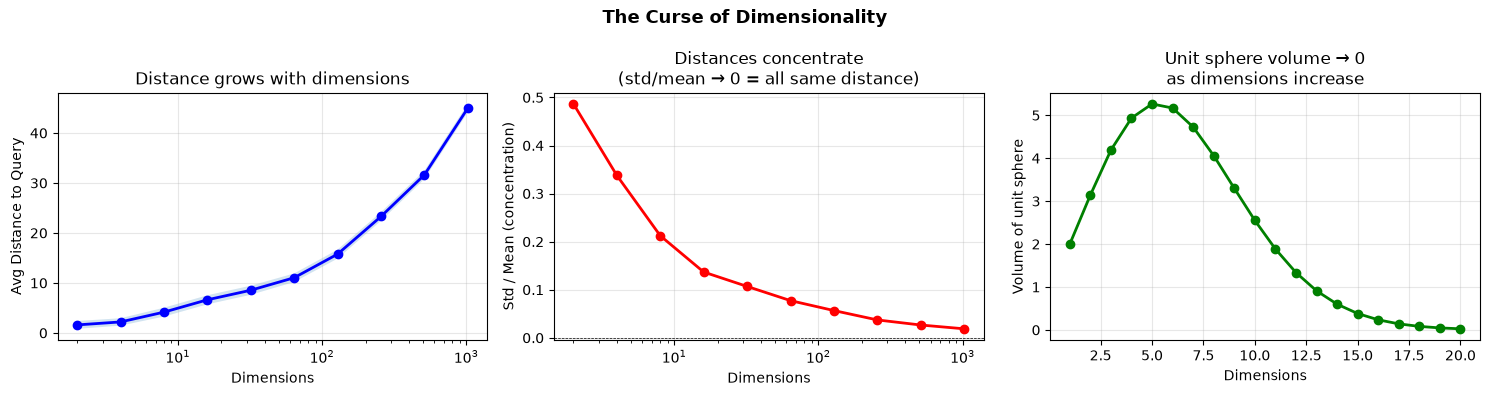

At 1024 dims: nearest and farthest neighbor nearly equidistant → exact search meaningless


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma

np.random.seed(0)

# ── Show how distances concentrate as dimensions grow ─────────────────────────
dimensions = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
n_points = 500
avg_dists, std_dists, dist_ratios = [], [], []

for d in dimensions:
    pts = np.random.randn(n_points, d)
    query = np.random.randn(1, d)
    dists = np.sqrt(np.sum((pts - query)**2, axis=1))
    avg_dists.append(dists.mean())
    std_dists.append(dists.std())
    # ratio = std/mean: smaller = more concentrated (curse)
    dist_ratios.append(dists.std() / dists.mean())

# ── Volume of unit sphere ─────────────────────────────────────────────────────
d_vals = np.arange(1, 21)
volumes = np.pi**(d_vals/2) / gamma(d_vals/2 + 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(dimensions, avg_dists, 'b-o', lw=2)
axes[0].fill_between(dimensions,
                      np.array(avg_dists) - np.array(std_dists),
                      np.array(avg_dists) + np.array(std_dists), alpha=0.2)
axes[0].set_xlabel('Dimensions'); axes[0].set_ylabel('Avg Distance to Query')
axes[0].set_title('Distance grows with dimensions')
axes[0].set_xscale('log'); axes[0].grid(True, alpha=0.3)

axes[1].plot(dimensions, dist_ratios, 'r-o', lw=2)
axes[1].set_xlabel('Dimensions'); axes[1].set_ylabel('Std / Mean (concentration)')
axes[1].set_title('Distances concentrate\n(std/mean → 0 = all same distance)')
axes[1].set_xscale('log'); axes[1].grid(True, alpha=0.3)
axes[1].axhline(0, color='black', lw=0.5, linestyle='--')

axes[2].plot(d_vals, volumes, 'g-o', lw=2)
axes[2].set_xlabel('Dimensions'); axes[2].set_ylabel('Volume of unit sphere')
axes[2].set_title('Unit sphere volume → 0\nas dimensions increase')
axes[2].grid(True, alpha=0.3)

plt.suptitle('The Curse of Dimensionality', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('curse_dimensionality.png', dpi=120, bbox_inches='tight')
plt.show()
print('At 1024 dims: nearest and farthest neighbor nearly equidistant → exact search meaningless')

## Exact vs Approximate Nearest Neighbor (ANN)

**Exact KNN complexity**: $O(n \cdot d)$ per query
- $n = 1{,}000{,}000$ vectors, $d = 1536$ dims → **1.5 billion multiply-adds per query**
- At 1ms per million ops → 1.5 seconds per query. Unacceptable.

**ANN** trades a small accuracy loss for orders-of-magnitude speedup:

$$\text{Recall@k} = \frac{|\text{ANN top-k} \cap \text{true top-k}|}{k}$$

- A good ANN index achieves **Recall@10 > 0.95** at **10-100× speedup**
- The tradeoff: build time, memory, and query-time recall are all tunable

In [4]:
import numpy as np
import time

np.random.seed(42)
n, d = 10_000, 128
vectors = np.random.randn(n, d).astype('float32')
query   = np.random.randn(1, d).astype('float32')
k = 10

# ── Brute-force exact KNN ─────────────────────────────────────────────────────
def exact_knn(vectors, query, k):
    dists = np.sqrt(np.sum((vectors - query)**2, axis=1))
    return np.argsort(dists)[:k]

# Warm up + time
exact_knn(vectors, query, k)   # warm up
t0 = time.perf_counter()
for _ in range(100):
    true_neighbors = exact_knn(vectors, query, k)
exact_time = (time.perf_counter() - t0) / 100

print(f"Exact KNN (brute force):")
print(f"  Time per query : {exact_time*1000:.3f} ms")
print(f"  Top-{k} indices: {true_neighbors}")
print(f"  Recall@{k}      : 1.000 (by definition — exact)")
print(f"  Complexity     : O(n·d) = O({n}·{d}) = O({n*d:,}) per query")
print(f"\n  At n=1M, d=1536 → O(1.5B) ops → ~1.5s/query → unusable")

Exact KNN (brute force):
  Time per query : 2.392 ms
  Top-10 indices: [2689 3260  321 3219 4921 4391 7865 5264 8681 6306]
  Recall@10      : 1.000 (by definition — exact)
  Complexity     : O(n·d) = O(10000·128) = O(1,280,000) per query

  At n=1M, d=1536 → O(1.5B) ops → ~1.5s/query → unusable


## Inverted File Index (IVF)

**Core idea**: Cluster vectors first, then search only within the nearest cluster(s).

**Algorithm**:
1. **Build**: k-means cluster all vectors into $k$ clusters. Store each vector under its cluster.
2. **Query**: Find the $p$ nearest cluster centroids. Search only vectors within those clusters.
3. **Search complexity**: $O(p \cdot \frac{n}{k} \cdot d)$ instead of $O(n \cdot d)$

**Speedup factor**: $\frac{k}{p}$ — with $k=100$ clusters and $p=5$ probes → **20× speedup**

**Recall tradeoff**: More probes ($p$) → higher recall, slower. Fewer probes → faster, lower recall.

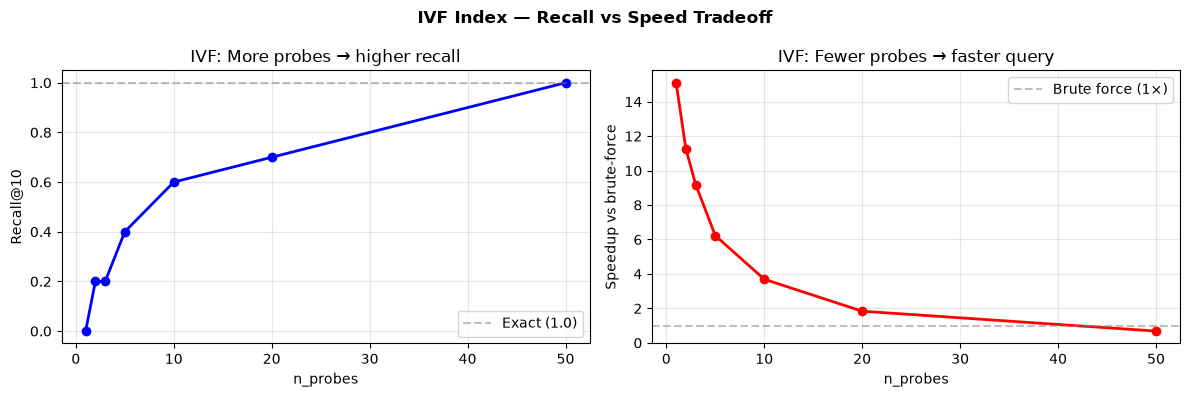

n_probes | Recall@10 | Speedup
       1 |   0.000   | 15.1×
       2 |   0.200   | 11.3×
       3 |   0.200   | 9.2×
       5 |   0.400   | 6.2×
      10 |   0.600   | 3.7×
      20 |   0.700   | 1.8×
      50 |   1.000   | 0.7×


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
import time

np.random.seed(42)
n, d = 10_000, 32   # smaller d for fast demo
vectors = np.random.randn(n, d).astype('float32')
query   = np.random.randn(1, d).astype('float32')
k_clusters = 50
K_NEIGHBORS = 10

# ── Build IVF index ───────────────────────────────────────────────────────────
kmeans = MiniBatchKMeans(n_clusters=k_clusters, random_state=42, n_init=3)
assignments = kmeans.fit_predict(vectors)   # assign each vector to a cluster

# Build inverted lists: cluster_id → list of vector indices
inverted_lists = {i: np.where(assignments == i)[0] for i in range(k_clusters)}

# ── IVF query ─────────────────────────────────────────────────────────────────
def ivf_search(vectors, query, kmeans, inverted_lists, k, n_probes):
    # 1. Find nearest centroids
    centroid_dists = np.sqrt(np.sum((kmeans.cluster_centers_ - query)**2, axis=1))
    nearest_clusters = np.argsort(centroid_dists)[:n_probes]
    # 2. Gather candidate indices
    candidates = np.concatenate([inverted_lists[c] for c in nearest_clusters])
    # 3. Exact search within candidates
    cand_vecs = vectors[candidates]
    dists = np.sqrt(np.sum((cand_vecs - query)**2, axis=1))
    top_k_local = np.argsort(dists)[:k]
    return candidates[top_k_local]

# ── Exact for ground truth ─────────────────────────────────────────────────────
exact_dists  = np.sqrt(np.sum((vectors - query)**2, axis=1))
true_top_k   = set(np.argsort(exact_dists)[:K_NEIGHBORS])

# ── Sweep n_probes ────────────────────────────────────────────────────────────
probe_vals  = [1, 2, 3, 5, 10, 20, 50]
recalls, speedups = [], []

t_exact = time.perf_counter()
for _ in range(200): _ = np.argsort(np.sqrt(np.sum((vectors - query)**2, axis=1)))[:K_NEIGHBORS]
exact_ms = (time.perf_counter() - t_exact) / 200 * 1000

for p in probe_vals:
    t0 = time.perf_counter()
    for _ in range(200): ivf_result = ivf_search(vectors, query, kmeans, inverted_lists, K_NEIGHBORS, p)
    ivf_ms = (time.perf_counter() - t0) / 200 * 1000
    recall = len(set(ivf_result) & true_top_k) / K_NEIGHBORS
    recalls.append(recall)
    speedups.append(exact_ms / max(ivf_ms, 0.001))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(probe_vals, recalls, 'b-o', lw=2)
axes[0].set_xlabel('n_probes'); axes[0].set_ylabel('Recall@10')
axes[0].set_title('IVF: More probes → higher recall')
axes[0].axhline(1.0, color='gray', linestyle='--', alpha=0.5, label='Exact (1.0)')
axes[0].grid(True, alpha=0.3); axes[0].legend()

axes[1].plot(probe_vals, speedups, 'r-o', lw=2)
axes[1].set_xlabel('n_probes'); axes[1].set_ylabel('Speedup vs brute-force')
axes[1].set_title('IVF: Fewer probes → faster query')
axes[1].axhline(1.0, color='gray', linestyle='--', alpha=0.5, label='Brute force (1×)')
axes[1].grid(True, alpha=0.3); axes[1].legend()

plt.suptitle('IVF Index — Recall vs Speed Tradeoff', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('ivf_tradeoff.png', dpi=120, bbox_inches='tight')
plt.show()

print("n_probes | Recall@10 | Speedup")
for p, r, s in zip(probe_vals, recalls, speedups):
    print(f"  {p:>6} |   {r:.3f}   | {s:.1f}×")

## HNSW — Hierarchical Navigable Small World

HNSW is the **dominant ANN algorithm** — used by default in Qdrant, Weaviate, and as an option in Faiss and pgvector.

### Inspiration: Small-World Networks
In social networks, any two people are connected by ~6 hops ("six degrees of separation"). HNSW builds a similar multi-layer graph on your vectors.

### Structure
- **Multiple layers**: Layer $L$ at the top (sparse, long-range links), Layer 0 at the bottom (dense, local links)
- **Each node** appears in layers 0 through $l_{max}$, where $l_{max}$ is drawn from an exponential distribution
- **Each node at each layer** connects to its $M$ nearest neighbors

### Insertion
1. Randomly assign the new node's maximum layer: $l \sim \lfloor -\ln(\text{Uniform}(0,1)) \cdot m_L \rfloor$
2. Starting from the top layer, greedily navigate to the new node's neighborhood
3. At each layer $\leq l$, connect to the $M$ nearest neighbors found

### Search
1. Start at the entry point in the top layer
2. Greedily move to the neighbor closest to the query
3. Descend to the next layer, repeat with a beam of `ef` candidates
4. At Layer 0, return the top-k from the explored set

### Key Parameters
| Parameter | Effect |
|-----------|--------|
| `M` (connections per node) | Higher → better recall, more memory, slower build |
| `ef_construction` | Build-time beam width → higher = better graph quality, slower build |
| `ef` | Query-time beam width → higher = better recall, slower query |

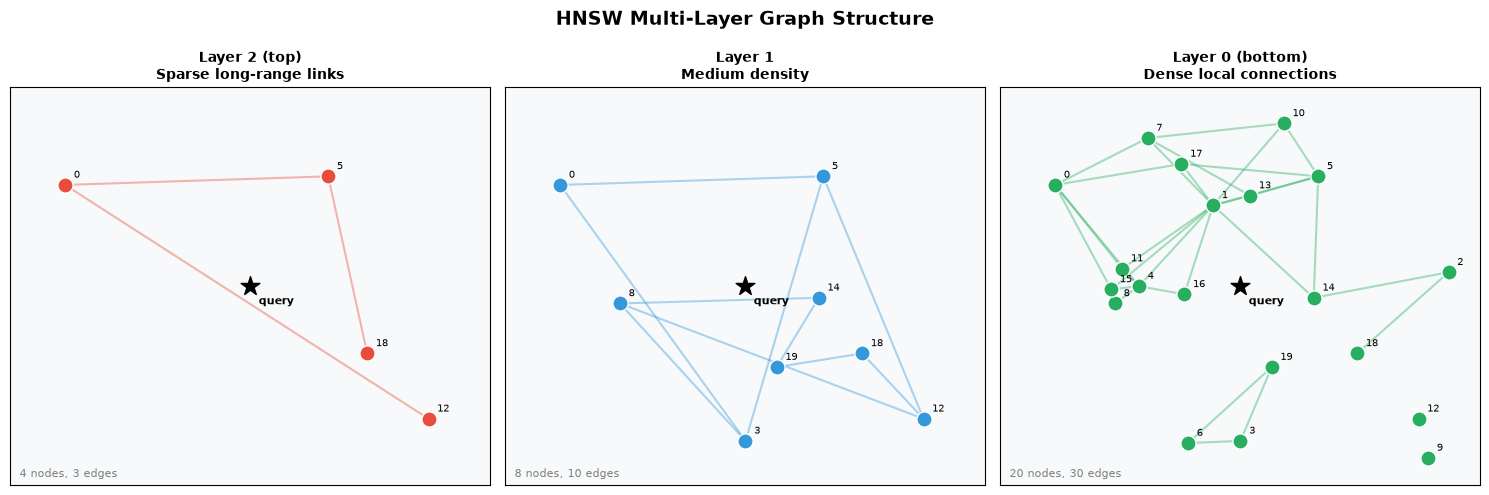

Top layers: coarse navigation (few nodes, long-range links)
Bottom layer: fine-grained search (all nodes, dense local connections)


In [6]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

np.random.seed(7)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('HNSW Multi-Layer Graph Structure', fontsize=14, fontweight='bold')

# Generate random 2D node positions
n_nodes = 20
positions = {i: np.random.rand(2) * 10 for i in range(n_nodes)}

layer_configs = [
    {'title': 'Layer 2 (top)\nSparse long-range links', 'nodes': [0,5,12,18], 'color': '#E74C3C', 'edges': [(0,12),(5,18),(0,5)]},
    {'title': 'Layer 1\nMedium density', 'nodes': [0,3,5,8,12,14,18,19], 'color': '#3498DB',
     'edges': [(0,3),(0,5),(3,8),(5,12),(8,14),(12,18),(14,19),(18,19),(3,5),(8,12)]},
    {'title': 'Layer 0 (bottom)\nDense local connections', 'nodes': list(range(n_nodes)), 'color': '#27AE60',
     'edges': [(i,j) for i in range(n_nodes) for j in range(i+1, n_nodes)
               if np.linalg.norm(np.array(positions[i])-np.array(positions[j])) < 3.5][:30]},
]

query_pos = np.array([5.0, 5.0])

for ax, cfg in zip(axes, layer_configs):
    ax.set_title(cfg['title'], fontsize=10, fontweight='bold')
    ax.set_xlim(-0.5, 10.5); ax.set_ylim(-0.5, 10.5)
    ax.set_facecolor('#F8F9FA')
    # Draw edges
    for i, j in cfg['edges']:
        p1, p2 = positions[i], positions[j]
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], color=cfg['color'], alpha=0.4, lw=1.5)
    # Draw nodes
    for nid in cfg['nodes']:
        ax.scatter(*positions[nid], s=120, color=cfg['color'], zorder=3, edgecolors='white', lw=1)
        ax.text(positions[nid][0]+0.2, positions[nid][1]+0.2, str(nid), fontsize=7)
    # Draw query
    ax.scatter(*query_pos, s=200, color='black', marker='*', zorder=5)
    ax.text(query_pos[0]+0.2, query_pos[1]-0.5, 'query', fontsize=8, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])
    ax.text(0.02, 0.02, f"{len(cfg['nodes'])} nodes, {len(cfg['edges'])} edges",
            transform=ax.transAxes, fontsize=8, color='gray')

plt.tight_layout()
plt.savefig('hnsw_layers.png', dpi=120, bbox_inches='tight')
plt.show()
print('Top layers: coarse navigation (few nodes, long-range links)')
print('Bottom layer: fine-grained search (all nodes, dense local connections)')

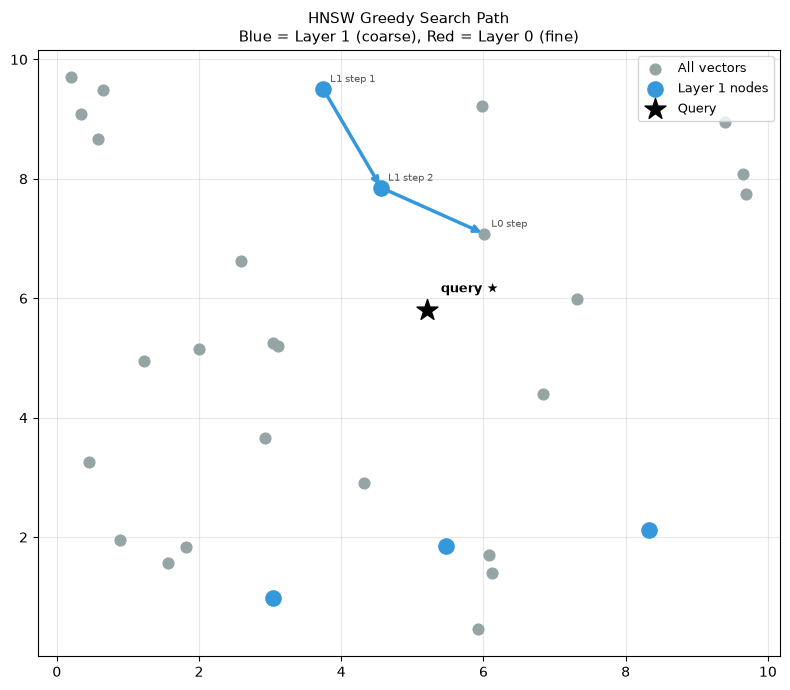

Search visits only ~10-30 nodes out of 30 — O(log n) complexity


In [7]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ── Simplified 2-layer HNSW to illustrate greedy search ──────────────────────
pts = np.random.rand(30, 2) * 10
query = np.array([5.2, 5.8])

# Layer 1: 5 random "highway" nodes
layer1_nodes = [0, 6, 12, 18, 24]

def greedy_step(current_idx, candidates, pts, query):
    """Move to the neighbor closest to query."""
    best, best_dist = current_idx, np.linalg.norm(pts[current_idx] - query)
    for c in candidates:
        d = np.linalg.norm(pts[c] - query)
        if d < best_dist:
            best, best_dist = c, d
    return best

def get_neighbors_layer0(idx, pts, M=4):
    dists = np.argsort([np.linalg.norm(pts[j]-pts[idx]) for j in range(len(pts))])
    return [j for j in dists[1:M+1]]

# Simulate search path
path = []
# Phase 1: Layer 1 — greedy search on highway nodes
entry = layer1_nodes[0]
current = entry
path.append(('L1', current))
for _ in range(3):
    nxt = greedy_step(current, layer1_nodes, pts, query)
    if nxt == current: break
    current = nxt
    path.append(('L1', current))

# Phase 2: Layer 0 — fine search from the best L1 node
path.append(('descend', current))
for _ in range(4):
    nbrs = get_neighbors_layer0(current, pts, M=5)
    nxt = greedy_step(current, nbrs, pts, query)
    if nxt == current: break
    current = nxt
    path.append(('L0', current))

# ── Visualize ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(pts[:,0], pts[:,1], s=60, color='#95A5A6', zorder=2, label='All vectors')
ax.scatter(pts[layer1_nodes,0], pts[layer1_nodes,1], s=120, color='#3498DB', zorder=3, label='Layer 1 nodes')

# Draw path
path_coords = [pts[p[1]] for p in path if p[0] != 'descend']
colors_p = ['#3498DB' if p[0]=='L1' else '#E74C3C' for p in path if p[0] != 'descend']
for i in range(len(path_coords)-1):
    c = '#3498DB' if colors_p[i]=='#3498DB' else '#E74C3C'
    ax.annotate('', xy=path_coords[i+1], xytext=path_coords[i],
                arrowprops=dict(arrowstyle='->', color=c, lw=2.5))

ax.scatter(*query, s=250, color='black', marker='*', zorder=5, label='Query')
ax.text(query[0]+0.2, query[1]+0.3, 'query ★', fontsize=9, fontweight='bold')

for i, p in enumerate(path):
    if p[0] != 'descend':
        lbl = f"L1 step {i+1}" if p[0]=='L1' else f"L0 step"
        ax.annotate(lbl, pts[p[1]], fontsize=7, color='#555',
                    xytext=(5,5), textcoords='offset points')

ax.set_title('HNSW Greedy Search Path\nBlue = Layer 1 (coarse), Red = Layer 0 (fine)', fontsize=11)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('hnsw_search_path.png', dpi=120, bbox_inches='tight')
plt.show()
print('Search visits only ~10-30 nodes out of 30 — O(log n) complexity')

## Product Quantization (PQ) — Vector Compression

### The Memory Problem
$$1{,}000{,}000 \text{ vectors} \times 1536 \text{ dims} \times 4 \text{ bytes} = 6.1 \text{ GB RAM}$$

At 100M vectors: **614 GB**. Impossible on a single machine.

### PQ Solution
1. **Split** each vector into $m$ equal subvectors: $\mathbf{x} = [\mathbf{x}^1, \mathbf{x}^2, \ldots, \mathbf{x}^m]$
2. **Quantize** each subspace with $k^*=256$ centroids learned from training data
3. **Encode** each subvector as a 1-byte index (0-255)

**Compressed size**: $m$ bytes per vector (instead of $d \times 4$ bytes)

**Compression ratio**: $\frac{d \times 4}{m}$ — with $d=128, m=8$: **64× compression**

### Approximate Distance via Lookup Table
$$d_{PQ}(\mathbf{q}, \mathbf{x}) \approx \sum_{j=1}^{m} d(\mathbf{q}^j, c^j_{b_j(\mathbf{x})})$$

Pre-compute a table of distances from the query subvectors to each centroid → distance = sum of $m$ table lookups. **No floating-point multiply needed.**

In [8]:
import numpy as np
from sklearn.cluster import MiniBatchKMeans

np.random.seed(42)

class ProductQuantizer:
    """Simple Product Quantizer — educational implementation."""
    def __init__(self, d, m, k_star=256):
        assert d % m == 0, f"d must be divisible by m"
        self.d = d          # original dimension
        self.m = m          # number of subspaces
        self.k_star = k_star  # centroids per subspace
        self.sub_d = d // m  # dimension of each subspace
        self.codebooks = []  # one KMeans per subspace

    def train(self, X):
        """Learn k* centroids for each of the m subspaces."""
        self.codebooks = []
        for j in range(self.m):
            sub = X[:, j*self.sub_d:(j+1)*self.sub_d]
            km = MiniBatchKMeans(n_clusters=self.k_star, random_state=j, n_init=3, max_iter=50)
            km.fit(sub)
            self.codebooks.append(km)

    def encode(self, X):
        """Compress vectors: (n, d) → (n, m) uint8."""
        codes = np.zeros((len(X), self.m), dtype=np.uint8)
        for j, km in enumerate(self.codebooks):
            sub = X[:, j*self.sub_d:(j+1)*self.sub_d]
            codes[:, j] = km.predict(sub)
        return codes

    def decode(self, codes):
        """Reconstruct approximate vectors: (n, m) → (n, d)."""
        recon = np.zeros((len(codes), self.d), dtype=np.float32)
        for j, km in enumerate(self.codebooks):
            recon[:, j*self.sub_d:(j+1)*self.sub_d] = km.cluster_centers_[codes[:, j]]
        return recon

    def approx_distances(self, query, codes):
        """Fast approx L2 distance via lookup table."""
        total = np.zeros(len(codes))
        for j, km in enumerate(self.codebooks):
            q_sub = query[j*self.sub_d:(j+1)*self.sub_d]
            table = np.sum((km.cluster_centers_ - q_sub)**2, axis=1)  # (k_star,)
            total += table[codes[:, j]]
        return np.sqrt(total)

# ── Demo ──────────────────────────────────────────────────────────────────────
d, m, n = 64, 8, 5000
X_train = np.random.randn(n, d).astype('float32')
X_test  = np.random.randn(100, d).astype('float32')
query   = np.random.randn(d).astype('float32')

pq = ProductQuantizer(d=d, m=m, k_star=16)   # k_star=16 for fast demo
pq.train(X_train)
codes = pq.encode(X_train)
recon = pq.decode(codes)

# Measure reconstruction error
recon_err = np.mean(np.sqrt(np.sum((X_train - recon)**2, axis=1)))

# Memory comparison
orig_bytes  = X_train.nbytes
coded_bytes = codes.nbytes

print(f"=== Product Quantization Results ===")
print(f"Original vectors  : {n} × {d} × 4 bytes = {orig_bytes:,} bytes ({orig_bytes/1024:.1f} KB)")
print(f"Compressed codes  : {n} × {m} × 1 byte  = {coded_bytes:,} bytes ({coded_bytes/1024:.1f} KB)")
print(f"Compression ratio : {orig_bytes/coded_bytes:.1f}×")
print(f"Reconstruction error (avg L2): {recon_err:.4f}")

# Compare exact vs PQ distances
exact_dists = np.sqrt(np.sum((X_train - query)**2, axis=1))
pq_dists    = pq.approx_distances(query, codes)
exact_top10 = set(np.argsort(exact_dists)[:10])
pq_top10    = set(np.argsort(pq_dists)[:10])
recall = len(exact_top10 & pq_top10) / 10
print(f"\nRecall@10 (PQ vs exact): {recall:.2f}")
print(f"Corr(exact_dist, pq_dist): {np.corrcoef(exact_dists, pq_dists)[0,1]:.4f}")
print(f"\n→ At scale: 1B vectors × 1536 dims → 6TB exact vs ~190GB with PQ (m=32)")

=== Product Quantization Results ===
Original vectors  : 5000 × 64 × 4 bytes = 1,280,000 bytes (1250.0 KB)
Compressed codes  : 5000 × 8 × 1 byte  = 40,000 bytes (39.1 KB)
Compression ratio : 32.0×
Reconstruction error (avg L2): 6.1922

Recall@10 (PQ vs exact): 0.00
Corr(exact_dist, pq_dist): 0.5300

→ At scale: 1B vectors × 1536 dims → 6TB exact vs ~190GB with PQ (m=32)


In [9]:
import faiss
import numpy as np
import time

np.random.seed(42)
d    = 128
n    = 50_000
k    = 10
X    = np.random.randn(n, d).astype('float32')
Q    = np.random.randn(100, d).astype('float32')  # 100 query vectors

def recall_at_k(true_ids, approx_ids, k):
    hits = sum(len(set(t[:k]) & set(a[:k])) for t, a in zip(true_ids, approx_ids))
    return hits / (len(true_ids) * k)

# ── 1. Flat (exact brute-force) ───────────────────────────────────────────────
flat = faiss.IndexFlatL2(d)
flat.add(X)
t0 = time.perf_counter(); _, true_I = flat.search(Q, k); t_flat = (time.perf_counter()-t0)*1000

# ── 2. IVF (partitioned approximate) ─────────────────────────────────────────
nlist = 200
ivf = faiss.IndexIVFFlat(faiss.IndexFlatL2(d), d, nlist)
ivf.train(X); ivf.add(X)
ivf.nprobe = 10
t0 = time.perf_counter(); _, ivf_I = ivf.search(Q, k); t_ivf = (time.perf_counter()-t0)*1000

# ── 3. HNSW ───────────────────────────────────────────────────────────────────
hnsw = faiss.IndexHNSWFlat(d, 32)  # M=32
hnsw.hnsw.efConstruction = 64
hnsw.add(X)
hnsw.hnsw.efSearch = 32
t0 = time.perf_counter(); _, hnsw_I = hnsw.search(Q, k); t_hnsw = (time.perf_counter()-t0)*1000

print(f"{'Index':<20} {'Time (100 queries)':>20} {'ms/query':>10} {'Recall@10':>12} {'Speedup':>10}")
print("-" * 76)
print(f"{'Flat (exact)':<20} {t_flat:>20.1f}ms {t_flat/100:>10.2f} {'1.000':>12} {'1.0×':>10}")
print(f"{'IVF (nprobe=10)':<20} {t_ivf:>20.1f}ms {t_ivf/100:>10.2f} {recall_at_k(true_I,ivf_I,k):>12.3f} {t_flat/max(t_ivf,0.1):>10.1f}×")
print(f"{'HNSW (M=32)':<20} {t_hnsw:>20.1f}ms {t_hnsw/100:>10.2f} {recall_at_k(true_I,hnsw_I,k):>12.3f} {t_flat/max(t_hnsw,0.1):>10.1f}×")
print("\n→ HNSW: best recall + speed tradeoff. IVF: more tunable, lower memory overhead.")

Index                  Time (100 queries)   ms/query    Recall@10    Speedup
----------------------------------------------------------------------------
Flat (exact)                         79.4ms       0.79        1.000       1.0×
IVF (nprobe=10)                       5.3ms       0.05        0.220       14.9×
HNSW (M=32)                          14.8ms       0.15        0.510        5.4×

→ HNSW: best recall + speed tradeoff. IVF: more tunable, lower memory overhead.


## Vector Database Landscape

| Database | Index Types | Filtering | Hosted | Best For |
|----------|-------------|-----------|--------|----------|
| **Pinecone** | HNSW, IVF | ✅ Metadata | ✅ Managed | Production RAG, fast start |
| **Qdrant** | HNSW | ✅ Payload filters | Both | Complex filtering + vectors |
| **Weaviate** | HNSW | ✅ GraphQL | Both | Knowledge graphs + vectors |
| **Milvus** | HNSW, IVF, PQ | ✅ | Both | Large-scale (>1B vectors) |
| **Chroma** | HNSW | ✅ | Self-hosted | Local dev, small projects |
| **pgvector** | HNSW, IVF | ✅ Full SQL | Self-hosted | Already on Postgres |
| **Faiss** | All types | ❌ (library only) | Library | Research, custom pipelines |

**When to choose**:
- **Already on Postgres** → pgvector (zero infra overhead)
- **Need metadata filtering** → Qdrant or Weaviate
- **>100M vectors** → Milvus
- **Fastest start, managed** → Pinecone
- **Local dev / notebook** → Chroma or Faiss

In [10]:
import numpy as np

# ── Complete RAG-style vector search pipeline (no API calls) ──────────────────
np.random.seed(0)

documents = [
    "Machine learning is a subset of artificial intelligence",
    "Neural networks are inspired by the human brain",
    "Vector databases store and retrieve embeddings efficiently",
    "HNSW is the most widely used ANN algorithm in production",
    "Transformers use self-attention to process sequences",
    "RAG combines retrieval with language model generation",
    "Python is the dominant language for ML engineering",
    "Feature stores serve pre-computed features at low latency",
]

def fake_embed(text: str, dim=64) -> np.ndarray:
    """Deterministic fake embedding (real system: call OpenAI/sentence-transformers)."""
    rng = np.random.default_rng(abs(hash(text)) % (2**31))
    v = rng.standard_normal(dim).astype('float32')
    return v / np.linalg.norm(v)  # L2-normalize for cosine sim via dot product

# Step 1: Embed and index all documents
doc_embeddings = np.array([fake_embed(d) for d in documents])

import faiss
dim = doc_embeddings.shape[1]
index = faiss.IndexFlatIP(dim)   # Inner Product on L2-normalized = cosine similarity
index.add(doc_embeddings)
print(f"Index built: {index.ntotal} documents at dim={dim}")

# Step 2: Query
query_text = "How do vector search indexes work?"
query_vec = fake_embed(query_text).reshape(1, -1)

scores, indices = index.search(query_vec, k=3)

# Step 3: Retrieved context
print(f"\nQuery: '{query_text}'")
print("\nTop-3 retrieved documents:")
retrieved_context = []
for rank, (idx, score) in enumerate(zip(indices[0], scores[0]), 1):
    print(f"  {rank}. [{score:.4f}] {documents[idx]}")
    retrieved_context.append(documents[idx])

# Step 4: How this feeds into an LLM
rag_prompt = f"""Answer the question using only the context below.

Context:
1. {retrieved_context[0]}
2. {retrieved_context[1]}
3. {retrieved_context[2]}

Question: {query_text}
Answer:"""
print(f"\n=== RAG Prompt sent to LLM ===")
print(rag_prompt)
print("\n→ LLM generates answer grounded in retrieved facts, not hallucinated knowledge")

Index built: 8 documents at dim=64

Query: 'How do vector search indexes work?'

Top-3 retrieved documents:
  1. [0.0962] Transformers use self-attention to process sequences
  2. [0.0937] Vector databases store and retrieve embeddings efficiently
  3. [0.0706] Feature stores serve pre-computed features at low latency

=== RAG Prompt sent to LLM ===
Answer the question using only the context below.

Context:
1. Transformers use self-attention to process sequences
2. Vector databases store and retrieve embeddings efficiently
3. Feature stores serve pre-computed features at low latency

Question: How do vector search indexes work?
Answer:

→ LLM generates answer grounded in retrieved facts, not hallucinated knowledge


## Key Takeaways

| Concept | What to remember |
|---------|------------------|
| **Cosine similarity** | Use for text embeddings — angle-based, magnitude-invariant |
| **Curse of dimensionality** | Exact search fails at scale — all distances converge |
| **IVF** | Cluster first, search cluster — tunable recall via `nprobe` |
| **HNSW** | Multi-layer small-world graph — best recall-speed tradeoff, O(log n) search |
| **PQ** | 32-64× memory compression via subspace quantization |
| **HNSW + PQ = IVF-HNSW-PQ** | Faiss `IndexHNSWPQ` — production setup for >10M vectors |

### Choosing an ANN Algorithm
```
< 100K vectors     → Flat (exact) — simple, no approximation needed
100K – 10M         → HNSW or IVF (nprobe tuning)
> 10M vectors      → HNSW + PQ, or IVF + PQ for memory efficiency  
Need metadata filter → Qdrant / Weaviate (pre-filter before ANN)
Already on Postgres  → pgvector with HNSW index
```

## Additional Learning Resources

- **HNSW paper**: Malkov & Yashunin (2018) — *Efficient and Robust ANN Search Using HNSW* (arXiv:1603.09320)
- **Faiss wiki**: https://github.com/facebookresearch/faiss/wiki
- **ANN Benchmarks**: https://ann-benchmarks.com — live recall/speed comparisons
- **Pinecone Learn**: https://www.pinecone.io/learn/ — excellent vector DB tutorials
- **Qdrant docs**: https://qdrant.tech/documentation/
- **Product Quantization paper**: Jégou et al. (2011) — *Product Quantization for Nearest Neighbor Search*